### Why Seaborn?

- provides a layer of abstraction hence simpler to use
- better aesthetics
- more graphs included

### Matplotlib vs Seaborn vs Plotly (Very Easy)

- **Matplotlib** – Basic, static plots with full control  
- **Seaborn** – Easy, beautiful statistical plots (EDA)  
- **Plotly** – Interactive plots for dashboards & web apps


### Seaborn Roadmap

Types of Functions

- **Figure Level** – High-level plotting functions that manage the entire figure and multiple subplots automatically.
- **Axis Level** – Low-level plotting functions that draw plots on a single Matplotlib Axes object.


# Main Classification

- **Relational Plot** – Used to visualize relationships between two numerical variables (e.g., scatter, line).
- **Distribution Plot** – Used to understand the distribution of a single variable (e.g., histograms, KDE).
- **Categorical Plot** – Used to compare values across different categories.
- **Regression Plot** – Used to visualize linear or non-linear relationships with fitted models.
- **Matrix Plot** – Used to visualize matrix-like data such as correlations or heatmaps.
- **Multiplots** – Used to create grids of multiple plots for comparative analysis.


### 1. Relational Plot

- to see the statistical relation between 2 or more variables.
- Bivariate Analysis

Plots under this section

- scatterplot
- lineplot

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px


In [10]:
tips = sns.load_dataset('tips')
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


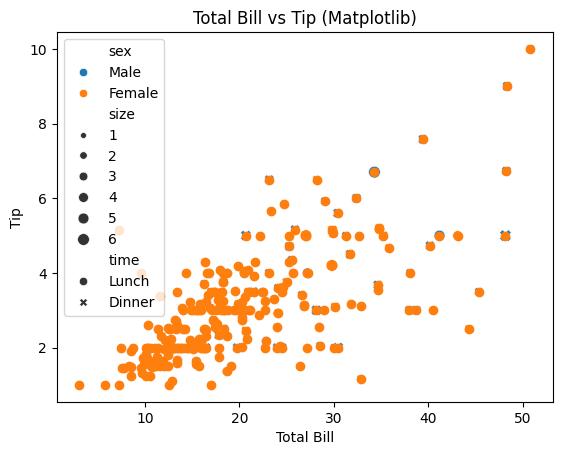

In [11]:
# --------------------------------------------------
# Scatter Plot (Axes-level Function)
# --------------------------------------------------

sns.scatterplot(
    data=tips,                   # dataset to be used
    x='total_bill',               # values on X-axis
    y='tip',                      # values on Y-axis
    hue='sex',                    # color separation based on gender
    style='time',                 # different marker styles for lunch/dinner
    size='size'                   # marker size based on group size
)

# drawing the same plot with plotly express
px.scatter(
    data_frame=tips,
    x='total_bill',
    y='tip',
    color='sex',        # same as hue
    symbol='time',      # same as style
    size='size',        # same as size
    title='Total Bill vs Tip (Plotly Express)'
).show()



# drawing the same plot with mathplotlib 
# scatter plot
plt.scatter(
    tips['total_bill'],
    tips['tip']
)

# labels
plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.title('Total Bill vs Tip (Matplotlib)')

plt.show()

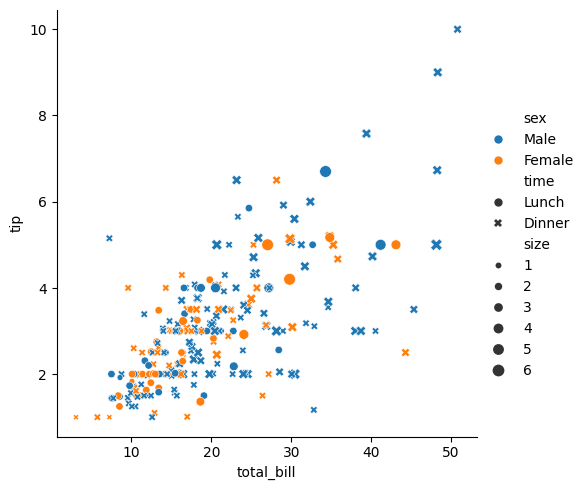

In [12]:
# --------------------------------------------------
# relplot → Figure-level Scatter Plot (Square Shape)
# --------------------------------------------------

sns.relplot(
    data=tips,                   # dataset to be used
    x='total_bill',               # X-axis values
    y='tip',                      # Y-axis values
    kind='scatter',               # specifies scatter plot
    hue='sex',                    # color encoding based on gender
    style='time',                 # marker style for lunch/dinner
    size='size'                   # marker size based on party size
)



### Scatter Plot using `relplot`

- **`relplot(kind="scatter")`** – Used to create scatter plots for showing relationships between two numerical variables.
- **`hue`** – Adds color grouping based on a categorical or numerical variable.
- **`size`** – Changes marker size to represent a third variable.
- **`style`** – Changes marker shape or line style to encode another categorical variable.

**Use case:**  
Visualize multi-dimensional data (x, y, color, size, shape) in a single scatter plot.


In [13]:
# line plot
gap = px.data.gapminder()
temp_df = gap[gap['country'] == 'India']
temp_df

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
696,India,Asia,1952,37.373,372000000,546.565749,IND,356
697,India,Asia,1957,40.249,409000000,590.061996,IND,356
698,India,Asia,1962,43.605,454000000,658.347151,IND,356
699,India,Asia,1967,47.193,506000000,700.770611,IND,356
700,India,Asia,1972,50.651,567000000,724.032527,IND,356
701,India,Asia,1977,54.208,634000000,813.337323,IND,356
702,India,Asia,1982,56.596,708000000,855.723538,IND,356
703,India,Asia,1987,58.553,788000000,976.512676,IND,356
704,India,Asia,1992,60.223,872000000,1164.406809,IND,356
705,India,Asia,1997,61.765,959000000,1458.817442,IND,356


In [14]:
# --------------------------------------------------
# Line Plot using Gapminder Dataset (India)
# --------------------------------------------------

# --------------------------------------------------
# Line Plot: Life Expectancy over Years eiht plotly express
# --------------------------------------------------
fig = px.line(
    temp_df,
    x='year',                                                # X-axis: Year
    y='lifeExp',                                             # Y-axis: Life Expectancy
    title='Life Expectancy in India Over Time',              # plot title
    markers=True                                             # show markers on line
)

fig.show()


<Axes: xlabel='year', ylabel='lifeExp'>

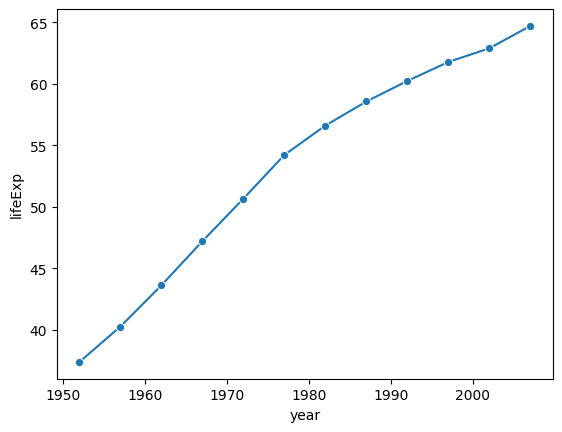

In [15]:
# --------------------------------------------------
# Line Plot (Axes-level Function) with Markers with seaborn
# --------------------------------------------------

sns.lineplot(
    data=temp_df,                # filtered dataset (India only)
    x='year',                     # X-axis: Year
    y='lifeExp',                  # Y-axis: Life Expectancy
    marker='o'                    # enables circular markers at each data point
)


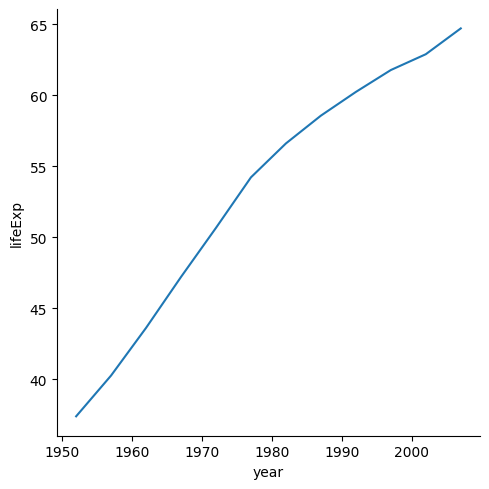

In [16]:
# using relpplot
sns.relplot(data=temp_df, x='year', y='lifeExp', kind='line')

# hue styling

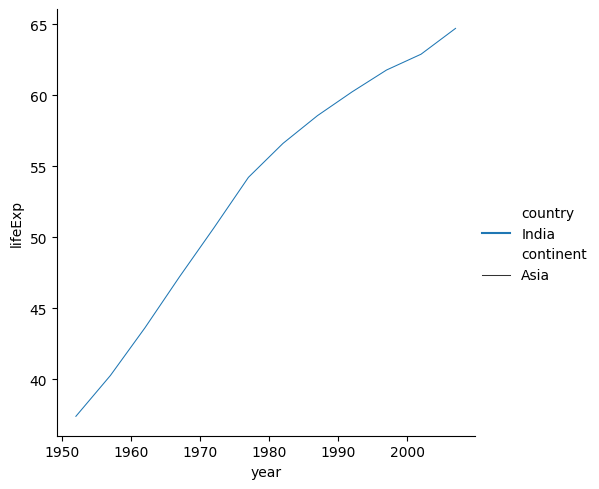

In [ ]:
# --------------------------------------------------
# relplot → Figure-level Line Plot
# Hue, Style, and Size Mapping
# --------------------------------------------------

sns.relplot(
    kind='line',                    # specifies line plot
    data=temp_df,                   # filtered dataset (India, Brazil, Germany)
    x='year',                       # X-axis: Year
    y='lifeExp',                    # Y-axis: Life Expectancy
    hue='country',                  # different colors for each country
    style='continent',              # different line styles per continent
    size='continent'                # line thickness based on continent
)


<Axes: xlabel='year', ylabel='lifeExp'>

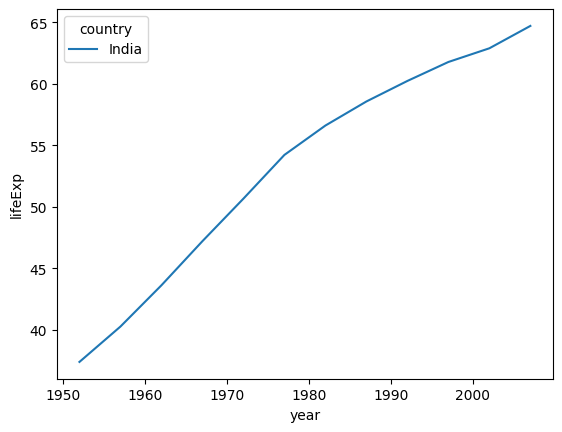

In [18]:
# --------------------------------------------------
# Line Plot (Axes-level Function)
# --------------------------------------------------

sns.lineplot(
    data=temp_df,                   # filtered dataset (India, Brazil, Germany)
    x='year',                        # X-axis: Year
    y='lifeExp',                     # Y-axis: Life Expectancy
    hue='country'                   # different colored lines for each country
)

# NOTE:
# Lineplot is an AXES-level function,
# isliye yeh graph FIGURE ke andar draw hota hai.
# Iske paas sirf AXES ka control hota hai,
# poori figure (size, layout, facets) ka nahi.


# Facet plot

A facet plot splits one graph into multiple small graphs (subplots) based on categorical variables, so you can compare patterns easily.

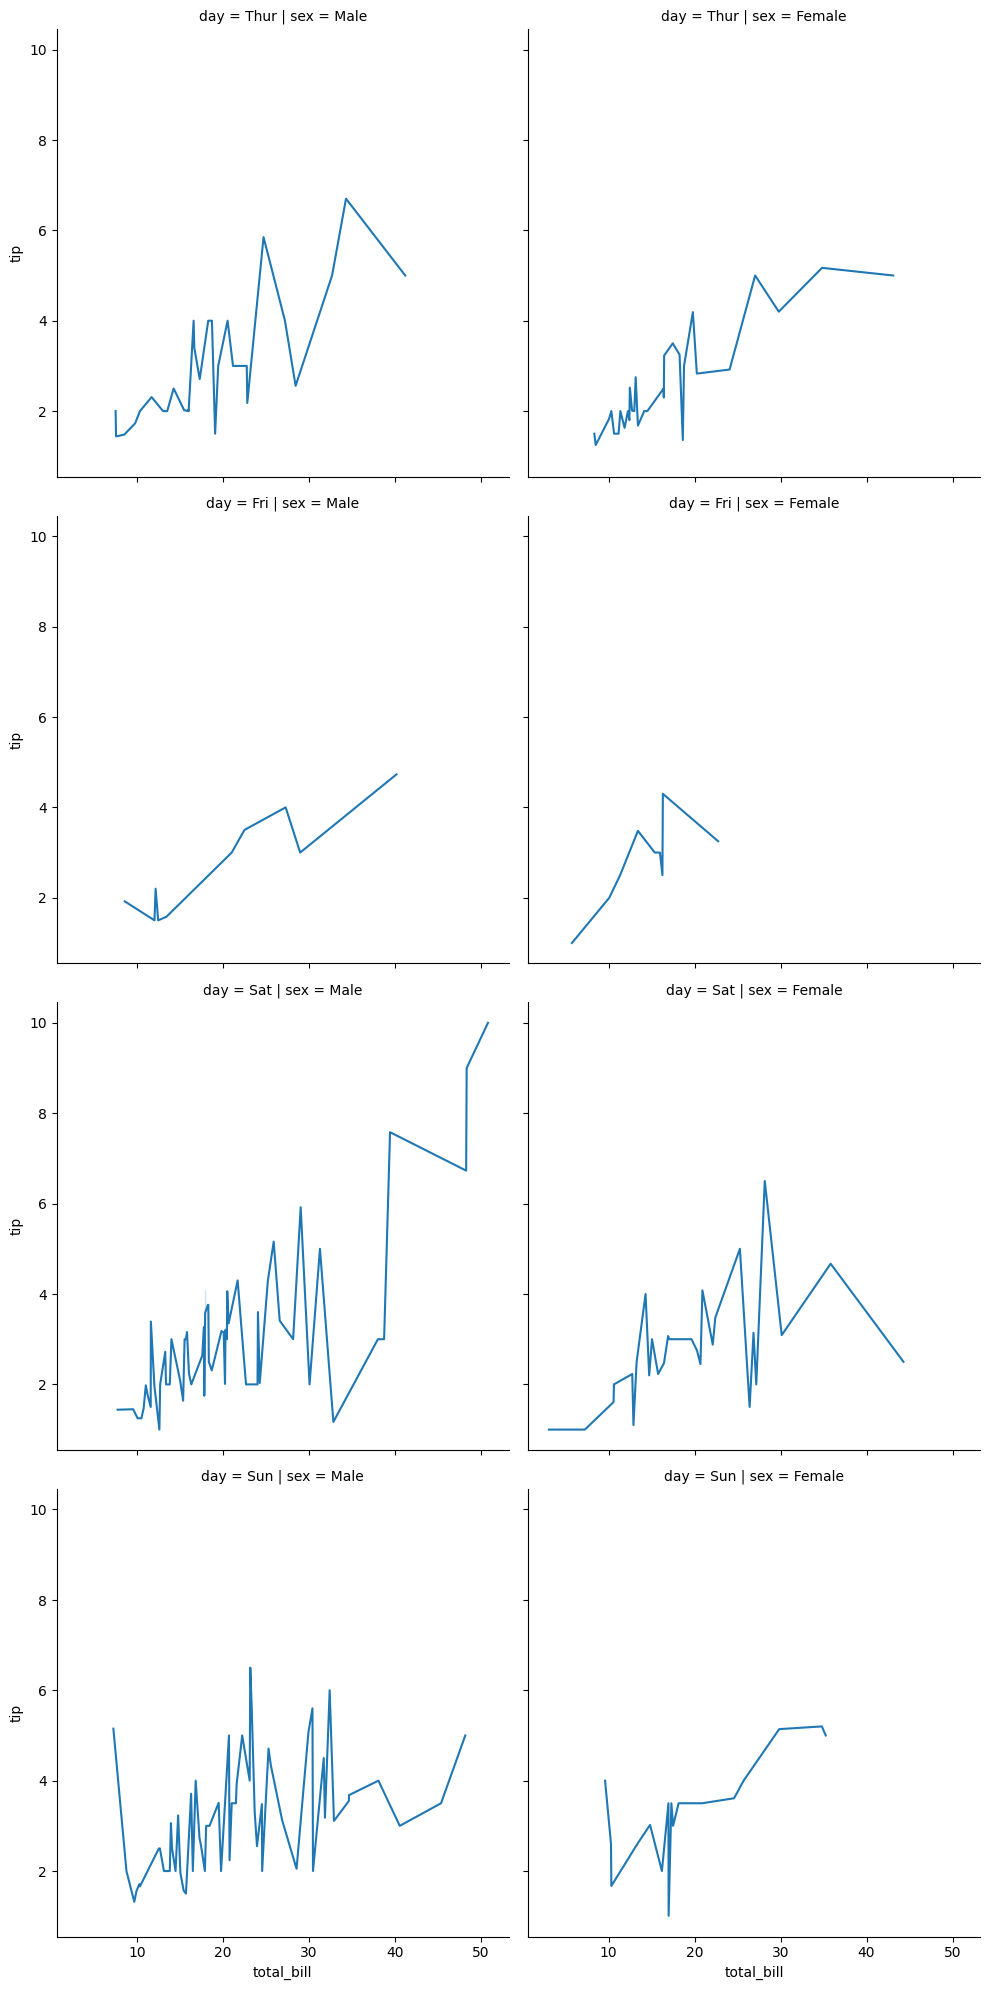

In [19]:
# --------------------------------------------------
# Facet Plot → Figure-level Function
# Works ONLY with relplot()
# --------------------------------------------------

sns.relplot(
    data=tips,                     # dataset
    x='total_bill',                # X-axis
    y='tip',                       # Y-axis
    kind='line',                   # line plot
    col='sex',                     # create separate columns based on sex
    row='day'                      # create separate rows based on day
)


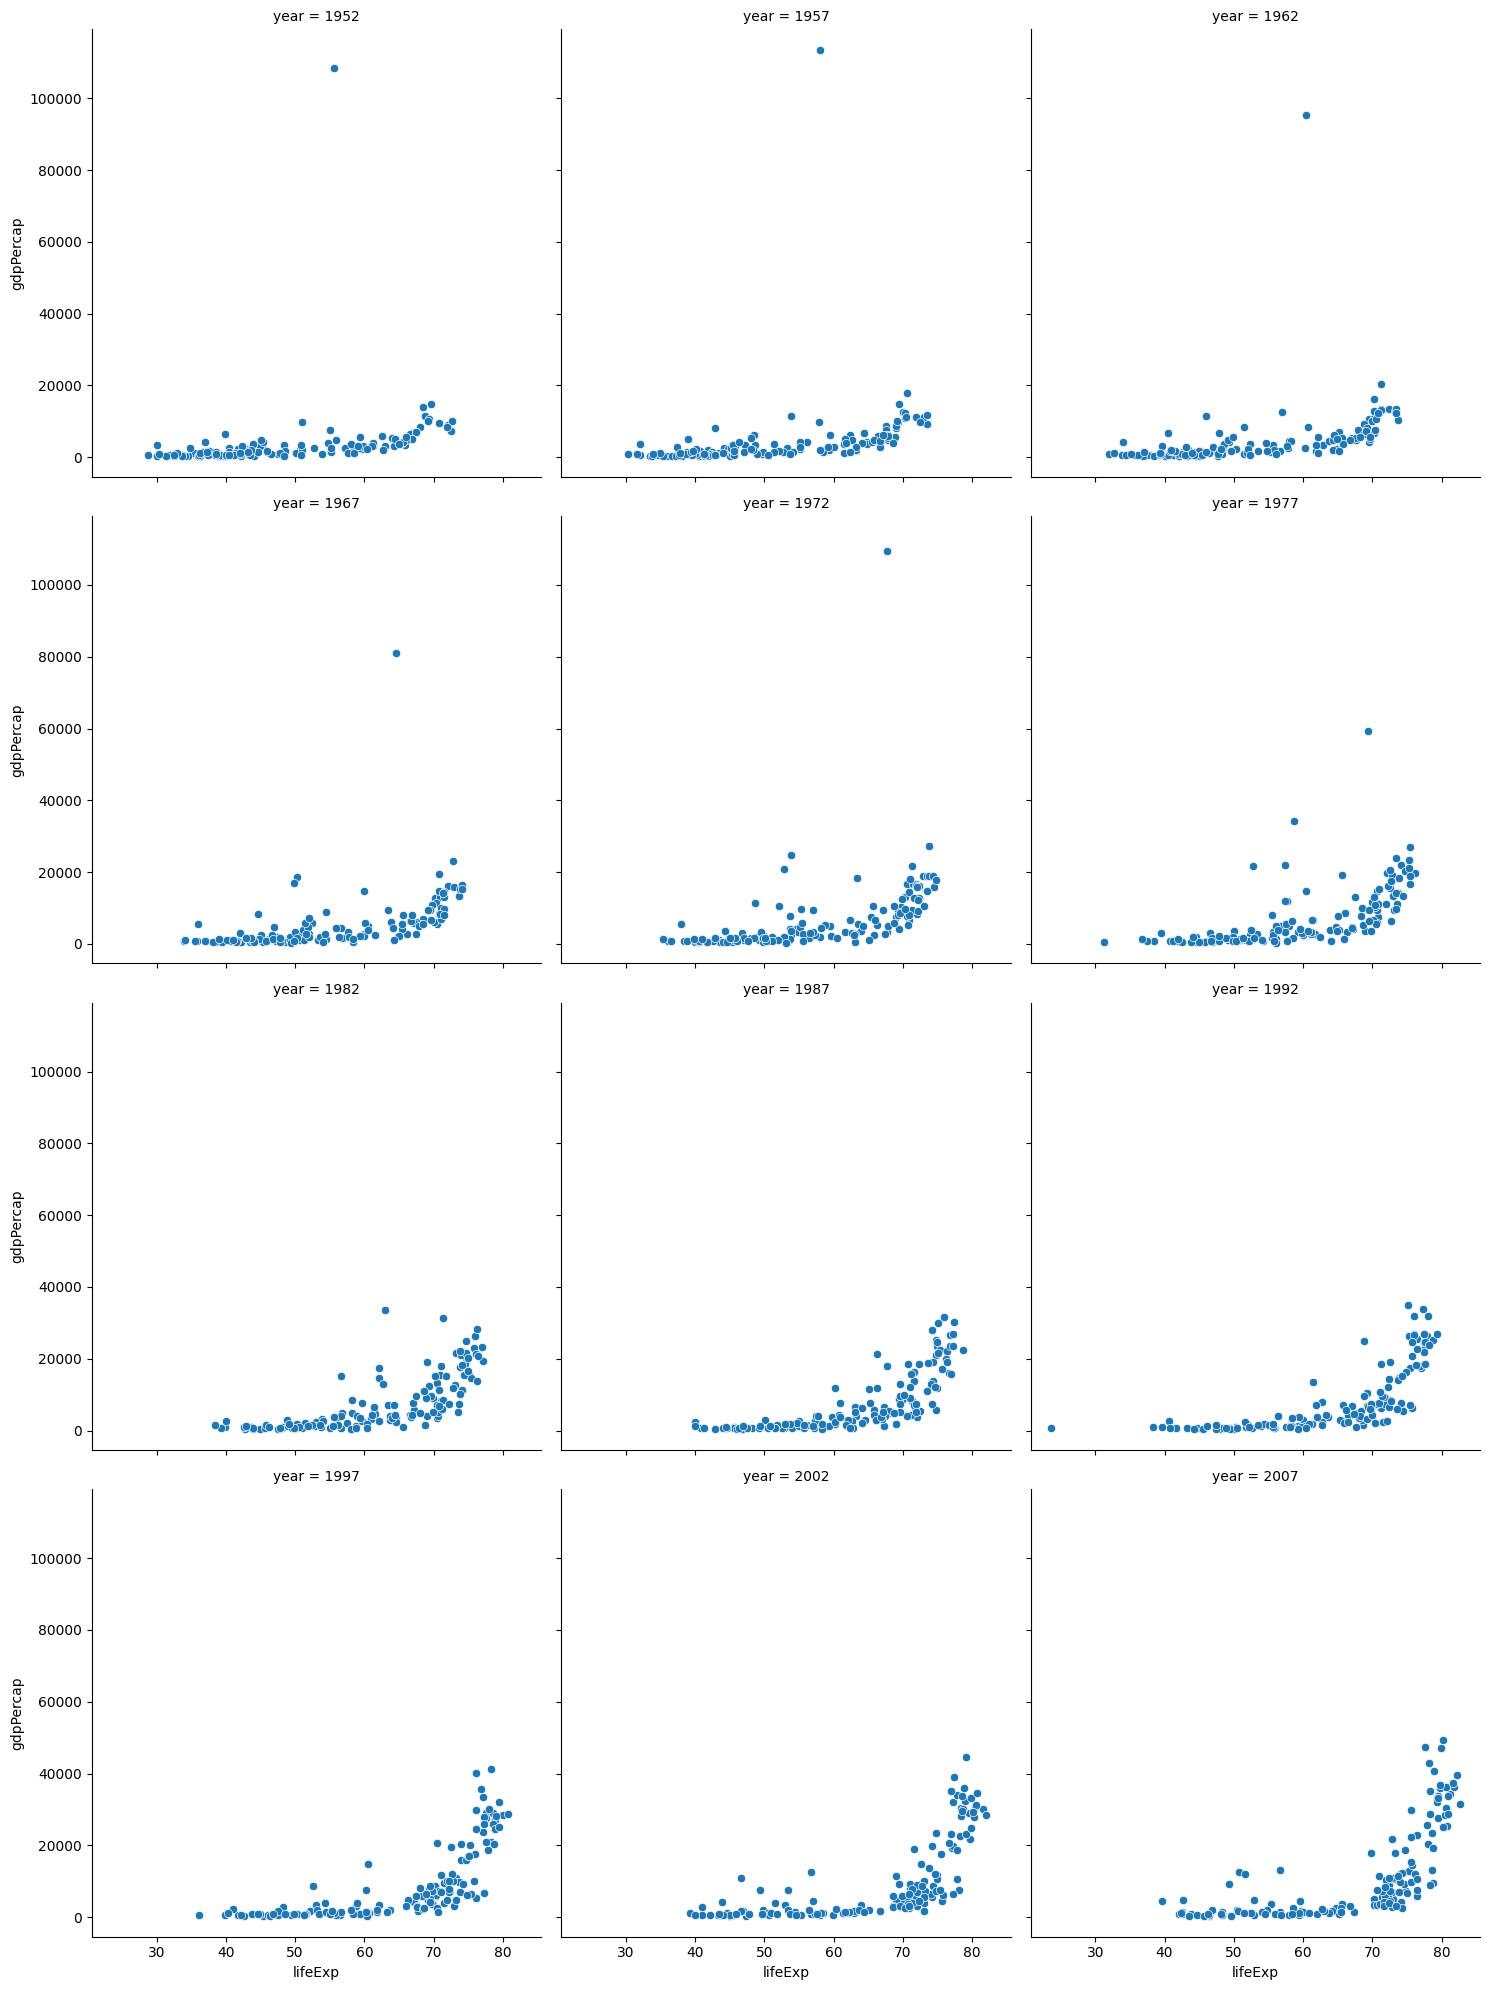

In [20]:
# --------------------------------------------------
# Facet Plot using col_wrap (Figure-level Function)
# --------------------------------------------------

sns.relplot(
    data=gap,                     # gapminder dataset
    x='lifeExp',                  # X-axis: Life Expectancy
    y='gdpPercap',                # Y-axis: GDP per Capita
    kind='scatter',               # scatter plot
    col='year',                   # create a facet for each year
    col_wrap=3                    # wrap columns into rows (3 plots per row)
)


### 2. Distribution Plots

- Used for **univariate analysis**
- Helps understand the **shape of the data distribution**
- Shows the **range of observations**
- Gives insight into **central tendency** (mean/median)
- Helps identify **bimodal or multimodal** data
- Useful for detecting **outliers**

Plots under Distribution Plot
- **histplot** – Displays frequency distribution using bins
- **kdeplot** – Shows a smooth probability density curve
- **rugplot** – Displays individual data points along the axis


### Distribution Plot Levels

- **Figure-level → `displot`** – High-level function that creates distribution plots with automatic figure and subplot management.
- **Axes-level → `histplot`** – Draws histogram on a specific Matplotlib axis.
- **Axes-level → `kdeplot`** – Draws a smooth density curve on a specific axis.
- **Axes-level → `rugplot`** – Draws tick marks for individual observations on the axis.


<Axes: xlabel='total_bill', ylabel='Count'>

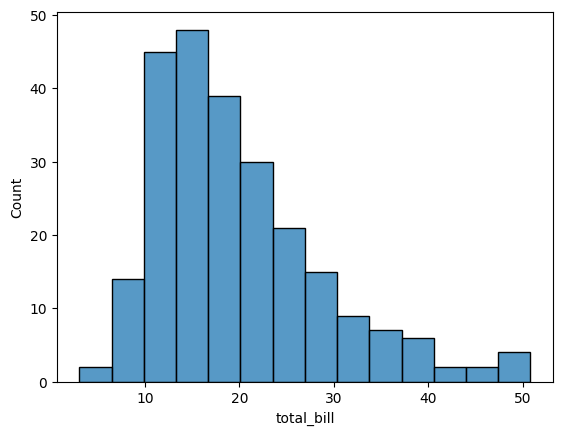

In [21]:
# --------------------------------------------------
# Univariate Histogram (Axes-level Function)
# --------------------------------------------------

sns.histplot(
    data=tips,                   # dataset
    x='total_bill'                # single numerical variable (univariate)
)


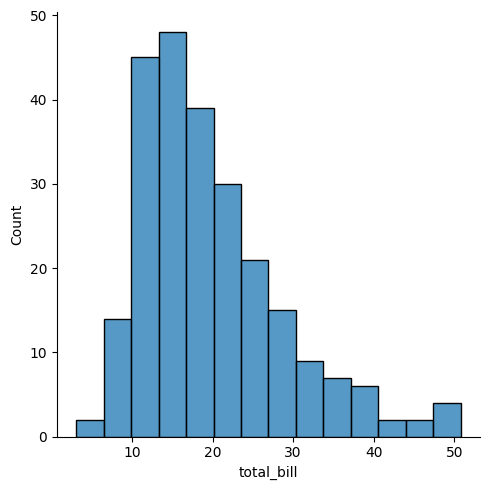

In [22]:
# --------------------------------------------------
# Distribution Plot (Figure-level Function)
# --------------------------------------------------

sns.displot(
    data=tips,                   # dataset
    x='total_bill',               # numerical variable
    kind='hist'                   # histogram type
)


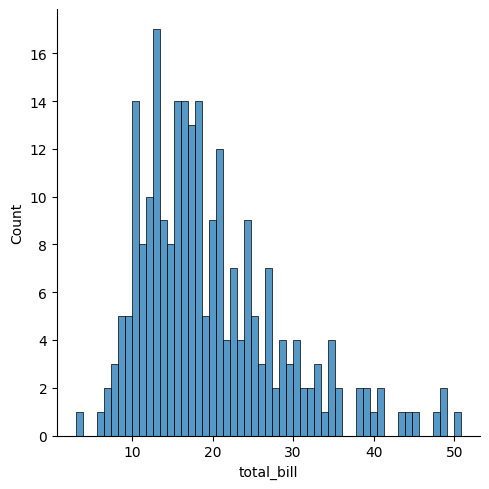

In [23]:
# --------------------------------------------------
# Histogram with bins parameter (Figure-level)
# --------------------------------------------------

sns.displot(
    data=tips,                   # dataset
    x='total_bill',               # numerical variable
    kind='hist',                  # histogram
    bins=55                       # number of bins (intervals)
)


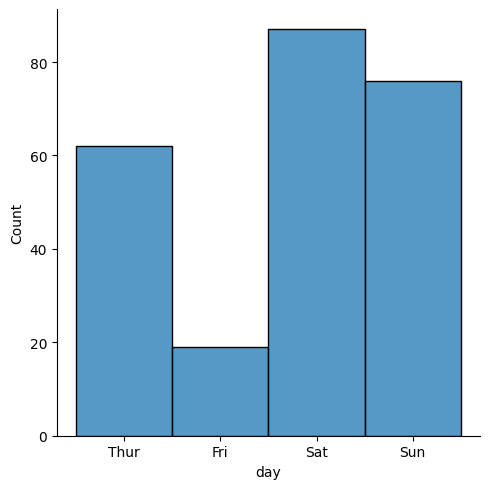

In [24]:
# It’s also possible to visualize the distribution of a categorical variable using the logic of a histogram. 
# Discrete bins are automatically set for categorical variables

# countplot
sns.displot(data=tips, x='day', kind='hist') 

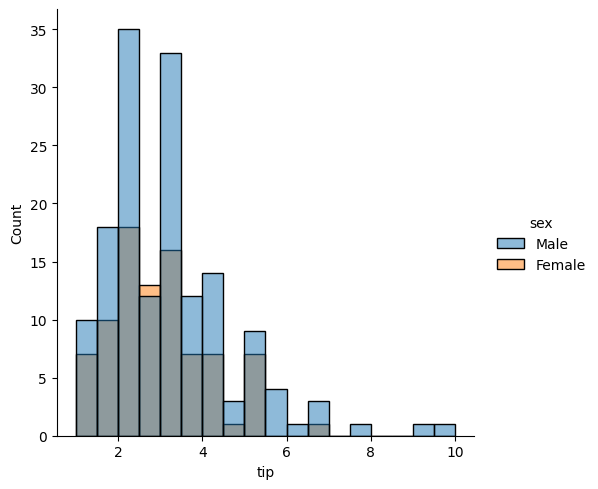

In [25]:
# --------------------------------------------------
# Histogram with Hue (Figure-level Function)
# --------------------------------------------------

sns.displot(
    data=tips,                   # dataset
    x='tip',                      # numerical variable
    kind='hist',                  # histogram
    hue='sex'                     # separate distributions by gender
)


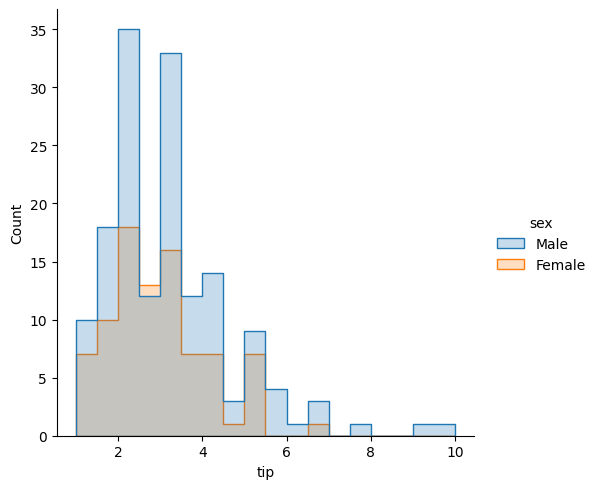

In [26]:
# --------------------------------------------------
# Histogram with Hue and Step Element (Figure-level)
# --------------------------------------------------

sns.displot(
    data=tips,                   # dataset
    x='tip',                      # numerical variable
    kind='hist',                  # histogram
    hue='sex',                    # separate distributions by gender
    element='step'                # draw histogram as outlined steps
)


In [27]:
titanic = sns.load_dataset('titanic')
titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


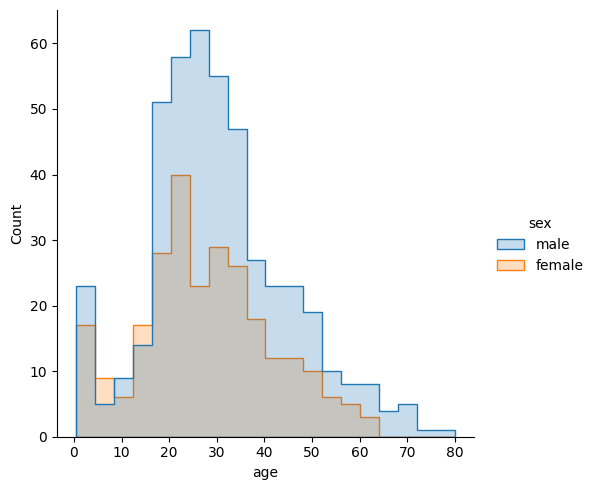

In [28]:
# --------------------------------------------------
# Histogram with Step Element and Hue (Figure-level)
# --------------------------------------------------

sns.displot(
    data=titanic,                # titanic dataset
    x='age',                     # numerical variable (Age)
    kind='hist',                 # histogram
    element='step',              # outlined (step-style) histogram
    hue='sex'                    # separate distributions by gender
)


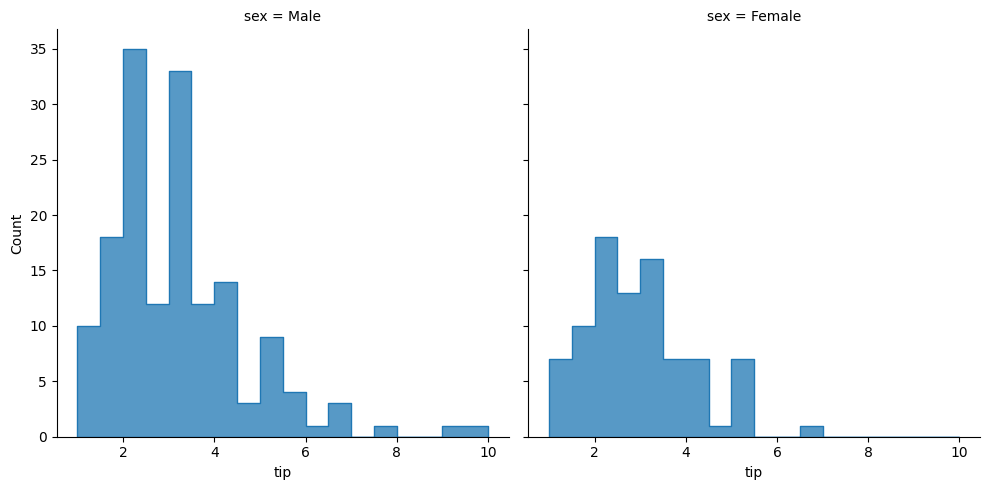

In [29]:
# --------------------------------------------------
# Faceting using col (Figure-level Function)
# NOTE: Faceting does NOT work with histplot()
# --------------------------------------------------

sns.displot(
    data=tips,                   # dataset
    x='tip',                      # numerical variable
    kind='hist',                  # histogram
    col='sex',                    # facet columns by sex
    element='step'                # outlined histogram
)


<Axes: xlabel='total_bill', ylabel='Density'>

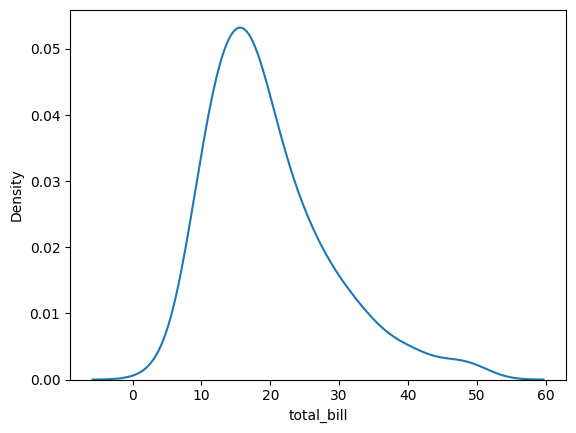

In [30]:
# --------------------------------------------------
# KDE Plot (Axes-level Function)
# --------------------------------------------------

# Rather than using discrete bins (like a histogram),
# a KDE plot smooths the observations using a Gaussian kernel,
# producing a continuous density estimate.

sns.kdeplot(
    data=tips,                   # dataset
    x='total_bill'                # numerical variable
)


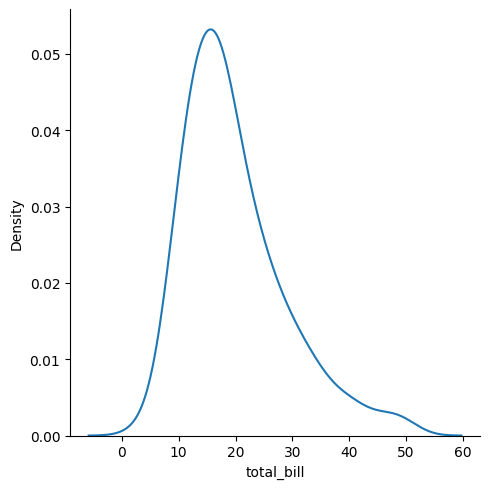

In [31]:
# --------------------------------------------------
# KDE Plot using displot (Figure-level Function)
# --------------------------------------------------

sns.displot(
    data=tips,                   # dataset
    x='total_bill',               # numerical variable
    kind='kde'                    # kernel density estimation
)


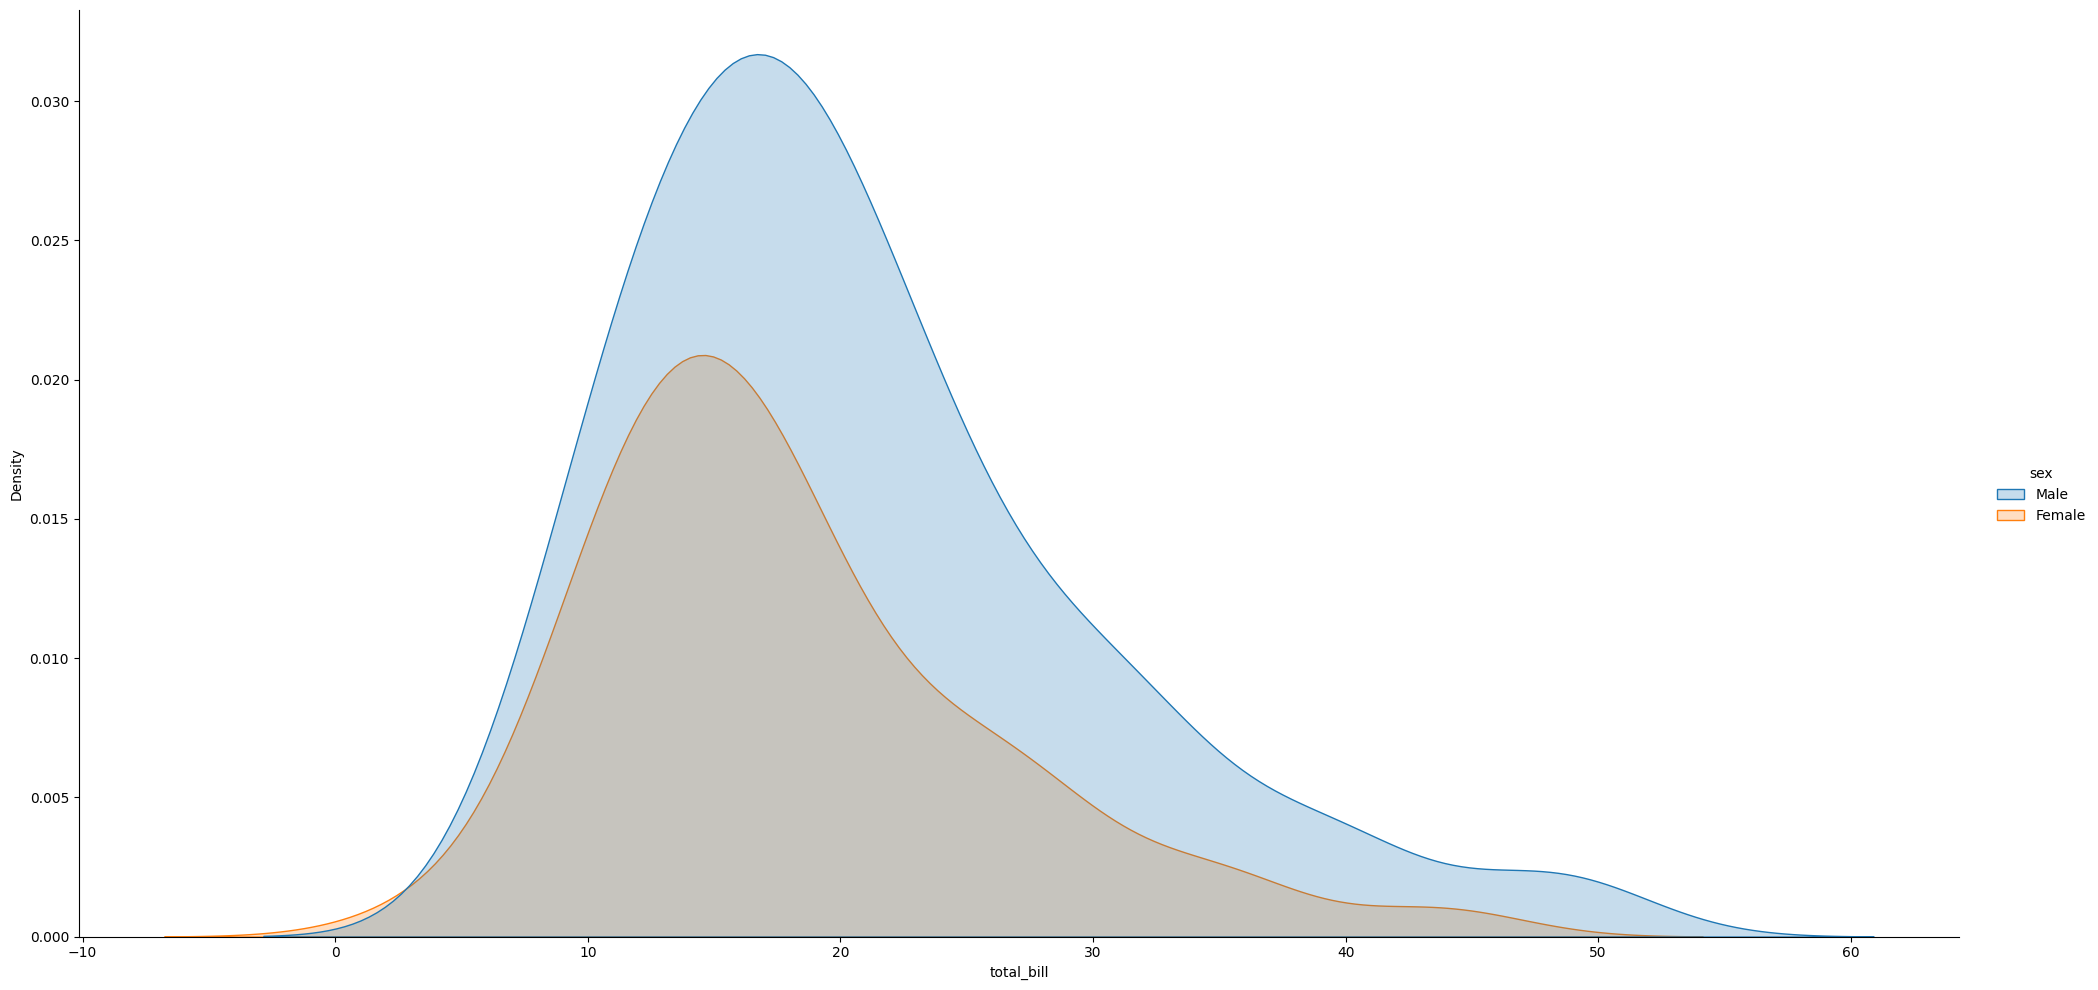

In [32]:
# --------------------------------------------------
# KDE Plot with Hue and Filled Area (Figure-level)
# --------------------------------------------------

sns.displot(
    data=tips,                   # dataset
    x='total_bill',               # numerical variable
    kind='kde',                   # kernel density estimation
    hue='sex',                    # separate distributions by gender
    fill=True,                    # fill the area under KDE curve
    height=10,                    # height of the figure (in inches)
    aspect=2                      # width = height × aspect
)


# Rugplot

# Plot marginal distributions by drawing ticks along the x and y axes.

<Axes: xlabel='total_bill', ylabel='Density'>

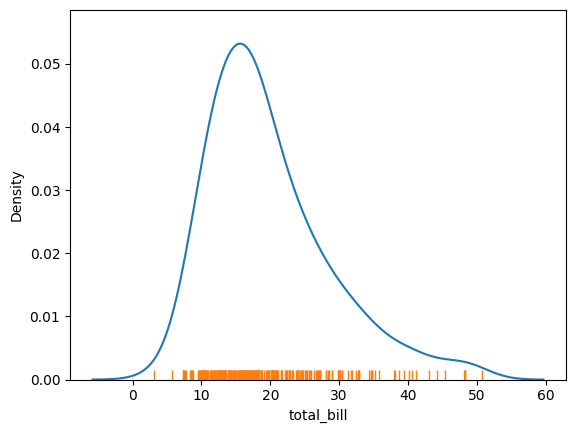

In [33]:
# --------------------------------------------------
# KDE Plot with Rug Plot (Axes-level Functions)
# --------------------------------------------------

# KDE plot shows the smooth density distribution
sns.kdeplot(
    data=tips,                   # dataset
    x='total_bill'                # numerical variable
)

# Rug plot shows individual data points as small ticks
# along the x-axis (marginal distribution)
sns.rugplot(
    data=tips,                   # same dataset
    x='total_bill'                # same variable
)


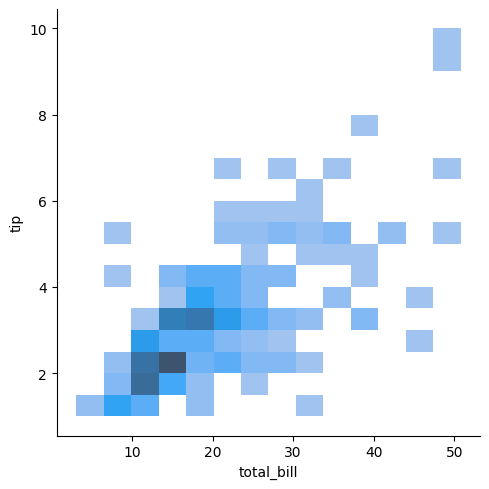

In [34]:
# --------------------------------------------------
# Bivariate Histogram (Figure-level Function)
# --------------------------------------------------

# A bivariate histogram divides the 2D space into rectangular bins
# and uses color intensity to show the number of observations
# in each rectangle.

sns.displot(
    data=tips,                   # dataset
    x='total_bill',               # X-axis variable
    y='tip',                      # Y-axis variable
    kind='hist'                   # 2D histogram
)


<Axes: xlabel='total_bill', ylabel='tip'>

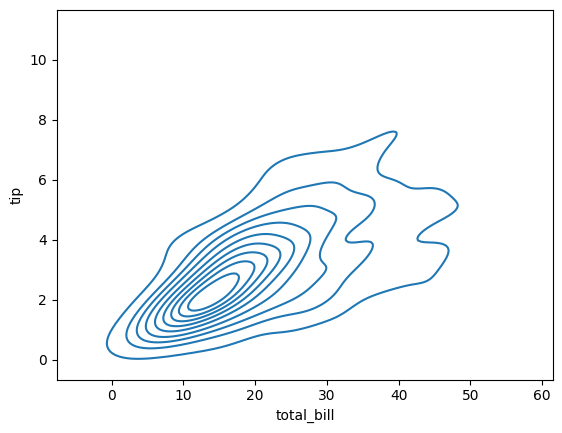

In [35]:
# Bivariate Kdeplot
# a bivariate KDE plot smoothes the (x, y) observations with a 2D Gaussian
sns.kdeplot(data=tips, x='total_bill', y='tip')

### 3. Matrix Plot

- Used to visualize **matrix-style data** in a color-encoded format
- Commonly used for **correlation analysis** and **pattern detection**

Plots under Matrix Plot
- **Heatmap** – Displays values in a matrix using color intensity
- **Clustermap** – Heatmap with hierarchical clustering to group similar rows and columns


<Axes: xlabel='year', ylabel='country'>

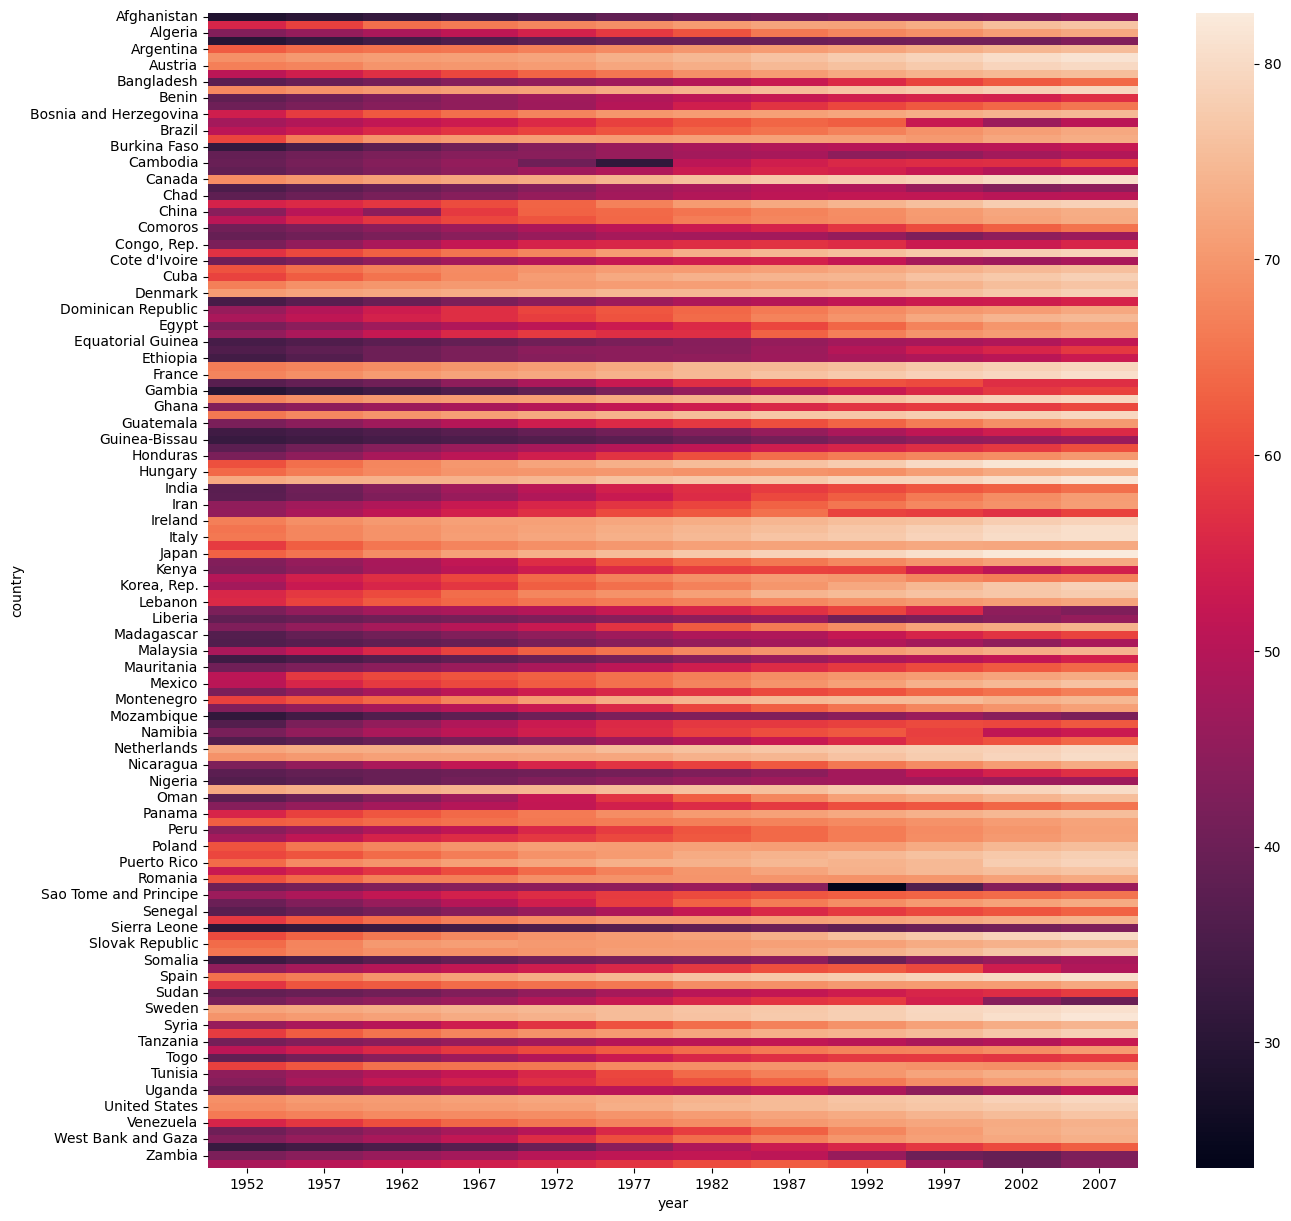

In [36]:
# --------------------------------------------------
# Heatmap (Axes-level Function)
# --------------------------------------------------

# Convert long-format data into matrix format
# rows    -> country
# columns -> year
# values  -> life expectancy
temp_df = gap.pivot(
    index='country',              # rows
    columns='year',               # columns
    values='lifeExp'              # cell values
)

# --------------------------------------------------
# Create Figure (Matplotlib controls the figure)
# --------------------------------------------------
plt.figure(figsize=(15, 15))      # set figure size manually

# --------------------------------------------------
# Draw Heatmap
# --------------------------------------------------
sns.heatmap(
    temp_df                        # matrix-style data
)


<Axes: xlabel='year', ylabel='country'>

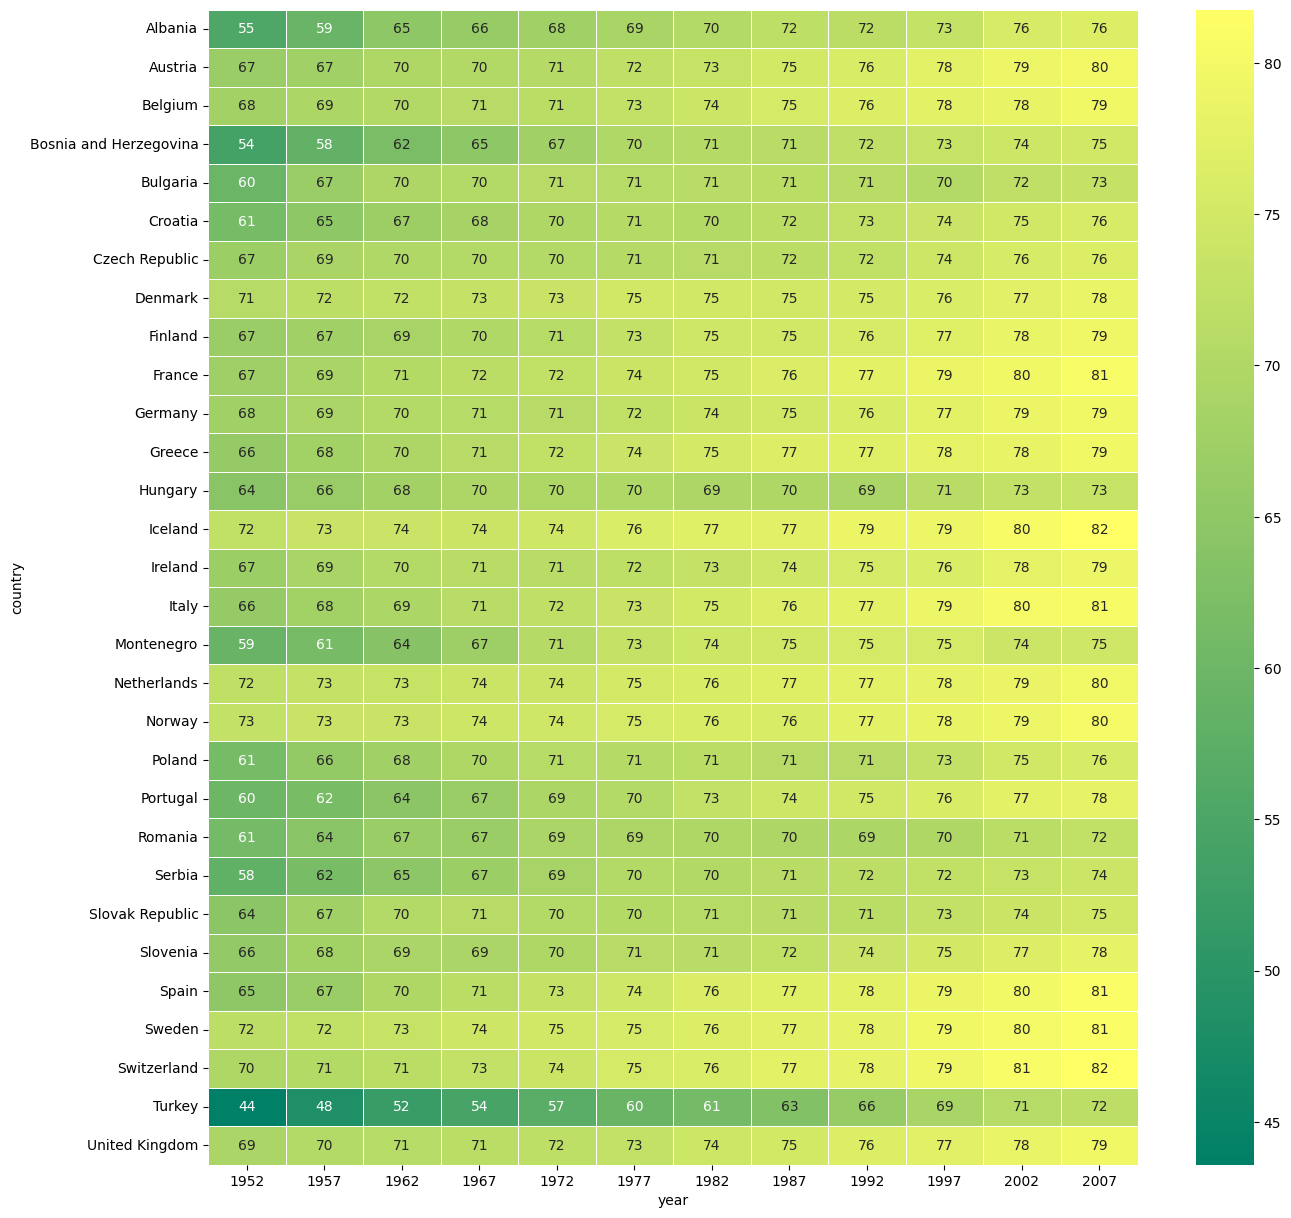

In [37]:
# --------------------------------------------------
# Heatmap with Annotations (Axes-level Function)
# --------------------------------------------------

# Filter only European countries
# Then convert long-format data into matrix form
temp_df = gap[gap['continent'] == 'Europe'].pivot(
    index='country',              # rows → countries
    columns='year',               # columns → years
    values='lifeExp'              # values → life expectancy
)

# --------------------------------------------------
# Create Figure (Matplotlib controls figure size)
# --------------------------------------------------
plt.figure(figsize=(15, 15))      # large figure for readability

# --------------------------------------------------
# Draw Heatmap with Annotations
# --------------------------------------------------
sns.heatmap(
    temp_df,
    annot=True,                   # show numerical values inside each cell
    linewidths=0.5,               # thickness of grid lines between cells
    cmap='summer'                 # color palette
)


### Heatmap Parameters

- **`cmap`** – Defines the color palette used to represent data values.
- **`linewidth`** – Controls the thickness of lines separating each cell in the heatmap.


# Clustermap

# Plot a matrix dataset as a hierarchically-clustered heatmap.

# This function requires scipy to be available.

iris = px.data.iris()
iris

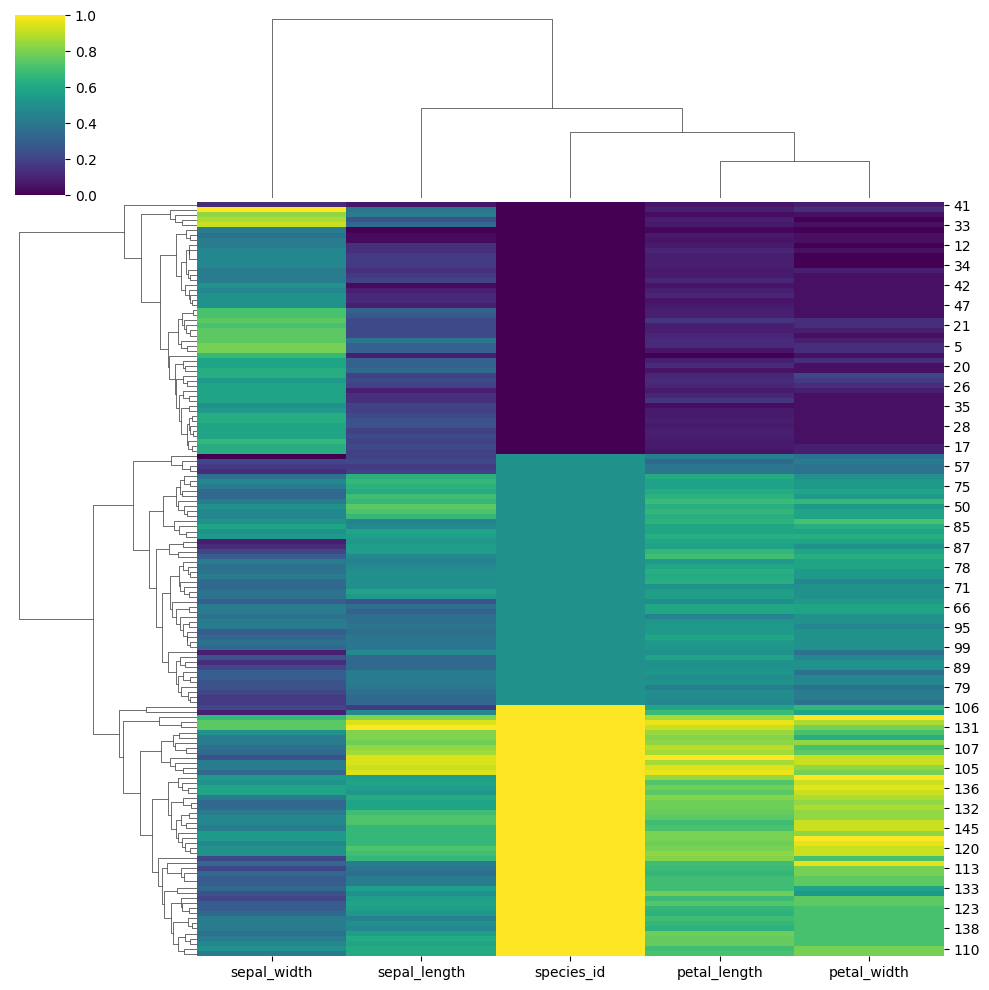

In [38]:
# Load Iris dataset (from Plotly Express)
iris = px.data.iris()                                     # classic flower dataset

# --------------------------------------------------
# Prepare Data for Clustermap
# (Only numerical columns are allowed)
# --------------------------------------------------

iris_num = iris.drop(columns=['species'])                # remove categorical column

# --------------------------------------------------
# Draw Clustermap
# --------------------------------------------------

sns.clustermap(
    iris_num,                                             # matrix-style numerical data
    cmap='viridis',                                       # color map
    standard_scale=1                                      # normalize columns (optional but useful)
)


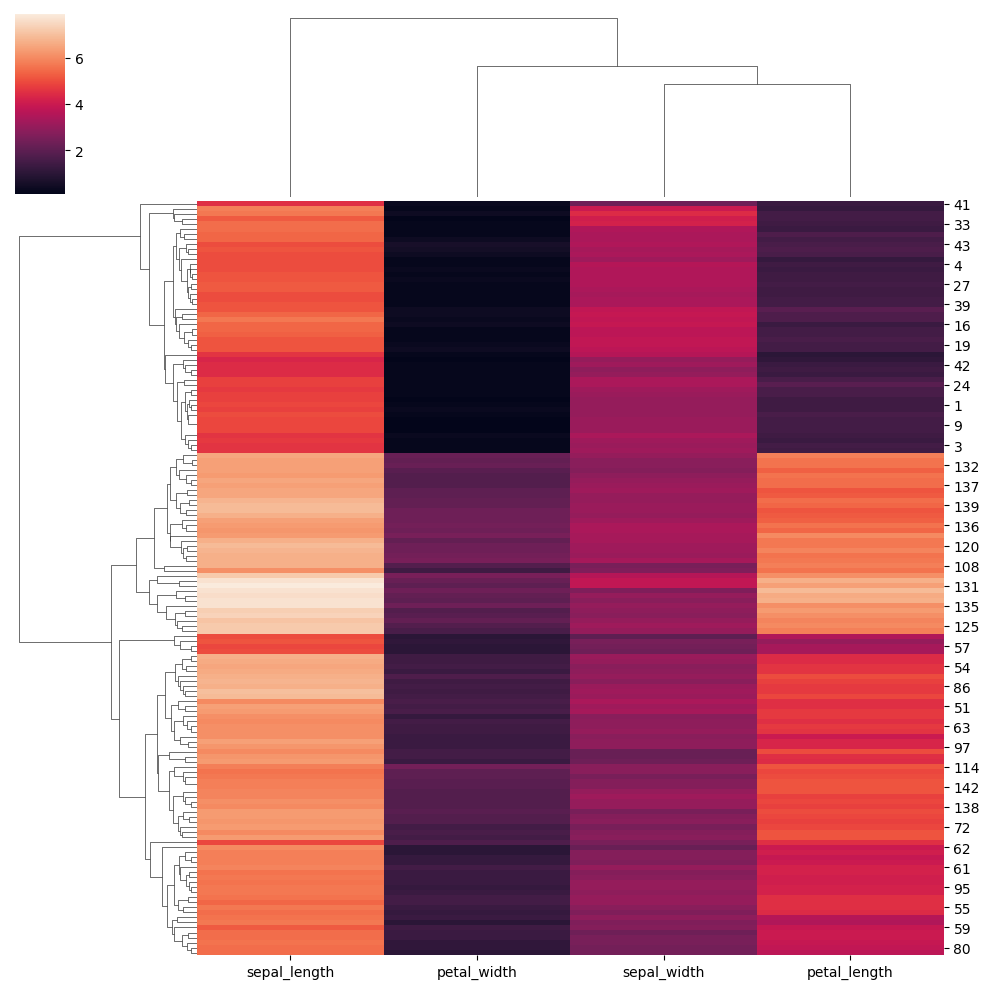

In [39]:
# --------------------------------------------------
# Clustermap using selected numerical columns
# --------------------------------------------------

sns.clustermap(
    iris.iloc[:, [0, 1, 2, 3]]     # select only numerical feature columns
)
